---
title: Optimization Solver by Q-CTRL Fire Opal
description: Start solving utility-scale optimization problems with the Fire Opal Optimization Solver by Q-CTRL
---

{/* cspell:ignore Sachdeva */}

# Optimization Solver by Q-CTRL Fire Opal

*See the [API reference](/docs/functions/q-ctrl-optimization-solver/api-reference)*

<Admonition type="note">
   Quantum Functions are a beta feature available only to IBM Quantum&reg; Premium Plan, Flex Plan, and On-Prem (through the IBM Quantum Platform API) Plan users. Beta features are subject to change.
</Admonition>

{/*
  DO NOT EDIT THIS CELL!!!
  This cell's content is generated automatically by a script. Anything you add
  here will be removed next time the notebook is run. To add new content, create
  a new cell before or after this one.
*/}

<Accordion>
<AccordionItem title="Package versions">

The code on this page was developed using the following requirements.
We recommend using these versions or newer.

```
qiskit-ibm-runtime~=0.47.0
sympy~=1.14.0
```
</AccordionItem>
</Accordion>

## Overview

With the Fire Opal Optimization Solver, you can solve utility-scale optimization problems on quantum hardware without requiring quantum expertise. Simply input the high-level problem definition, and the Solver takes care of the rest. The entire workflow is noise-aware and leverages [Fire Opal's Performance Management](/docs/functions/q-ctrl-performance-management/index) under the hood. The Solver consistently delivers accurate solutions to classically challenging problems, even at full-device scale on the largest IBM&reg; QPUs.

The Solver is flexible and can be used to solve combinatorial optimization problems defined as objective functions or arbitrary graphs. Problems do not have to be mapped to device topology. Both unconstrained and constrained problems are solvable, with constraints enforced as hard Hamming-weight-1 constraints rather than penalty terms. The examples included in this guide demonstrate how to solve an unconstrained and a constrained utility-scale optimization problem using different Solver input types. The first example involves a max-cut problem defined on a 156-node, 3-Regular graph, while the second example tackles a 50-node graph partitioning problem defined by a cost function.

To get access to the Optimization Solver, [contact Q-CTRL](https://form.typeform.com/to/uOAVDnGg?typeform-source=q-ctrl.com).

## Description

The Solver fully optimizes and automates the entire algorithm, from error suppression at the hardware level to efficient problem mapping and closed-loop classical optimization. Behind the scenes, the Solver's pipeline reduces errors at every stage, enabling the enhanced performance required to meaningfully scale. The underlying workflow is inspired by the Quantum Approximate Optimization Algorithm (QAOA), which is a hybrid quantum-classical algorithm. For a detailed summary of the full Optimization Solver workflow, refer to [the published manuscript](https://arxiv.org/abs/2406.01743).

![image.png](/docs/images/guides/qctrl-optimization/solver_workflow.svg)

To solve a generic problem with the Optimization Solver:
1. Define your problem as an objective function, a graph, or `SparsePauliOp` spin chain.
2. Connect to the function through the Quantum Functions Catalog.
3. Run the problem with the Solver and retrieve results.

### Accepted problem formats

- Polynomial expression representation of an objective function. Ideally created in Python with an existing SymPy Poly object and formatted into a string using [sympy.srepr](https://docs.sympy.org/latest/tutorials/intro-tutorial/printing.html#srepr).
- Graph representation of a specific problem type. The graph should be created using the networkx library in Python. It should then converted to a string by using the networkx function [`nx.readwrite.json_graph.adjacency_data`](https://networkx.org/documentation/stable/reference/readwrite/generated/networkx.readwrite.json_graph.adjacency_data.html).
- Spin chain representation of a specific problem. The spin chain should be represented as a `SparsePauliOp` object; see the [documentation](/docs/api/qiskit/qiskit.quantum_info.SparsePauliOp) for more details.

<Admonition type="note" title="Does this function support all IBM backends?">
If you want to use a backend that this function does not currently support, [reach out to Q-CTRL](https://form.typeform.com/to/iuujEAEI?typeform-source=q-ctrl.com) to add support.
</Admonition>

To access results from previous runs, see [how to retrieve previous quantum function jobs](/docs/ibm-quantum-platform/functions-get-started#list-previously-run-functions-jobs).

## Benchmarks

<Admonition type="caution" title="Disclaimer">
    Performance can depend on both the problem instance and subsequent processing steps. In some cases, classical samples and quantum-generated samples might achieve similar final solution quality after equivalent post-processing. Evaluation should therefore consider the complete optimization workflow.
</Admonition>

[Published benchmarking results](https://arxiv.org/abs/2406.01743) show that the Solver successfully solves problems with over 120 qubits, even outperforming previously published results on quantum annealing and trapped-ion devices. The following benchmark metrics provide a rough indication of the accuracy and scaling of problem types based on a few examples. Actual metrics may differ based on various problem features, such as the number of terms in the objective function (density) and their locality, number of variables, and polynomial order.

The "Number of qubits" indicated is not a hard limitation but represents rough thresholds where you can expect extremely consistent solution accuracy. Larger problem sizes have been successfully solved, and testing beyond these limits is encouraged.

Arbitrary qubit connectivity is supported across all problem types.

| Problem type    | Number of qubits | Example | Accuracy | Total time (s) | Runtime usage (s) | Number of iterations
| ---------  | ---------------- | -------------------------- | -------- | ---------- | ------------- |---- |
| Sparsely-connected quadratic problems  | 156 | 3-regular max-cut| 100%     | 1764     | 293          | 16 |
| Higher-order binary optimization | 156 | Ising spin-glass model | 100%      | 1461     | 272          | 16 |
| Densely-connected quadratic problems | 50 | Fully-connected max-cut| 100%      |  1758    | 268  | 12 |
| Constrained problem with hard constraints | 50 | Weighted graph partitioning with 8% edge density | 100%      | 1074     | 215 | 10 |

## Get started

First, authenticate using your [IBM Quantum API key](http://quantum.cloud.ibm.com/). Then, select the quantum function as follows. (This snippet assumes you've already [saved your account](/docs/ibm-quantum-platform/functions-get-started#install-qiskit-functions-catalog-client) to your local environment.)

In [1]:
from qiskit_ibm_catalog import FunctionsCatalog

catalog = FunctionsCatalog(channel="ibm_quantum_platform")

In [2]:
# Access Function
solver = catalog.load("q-ctrl/optimization-solver")

## Function sizes

Every job runs at one size: `S`, `M`, or `L`. If the size is too small, the job is rejected. If it is larger than needed, the job runs on a bigger compute profile than the work requires. See [Function sizes](/docs/managed-workflows/managed-workflow-compute-profiles#best-practice-match-sizes-to-problem-sizes) for how sizes work in general.

Pass the size to `solver.run()` with the `function_size` argument. For the Optimization Solver, the size depends on the number of binary decision variables and the interaction density of the problem.

Interaction density is the fraction of possible variable pairs that appear together in at least one term of the objective function or constraints. Each distinct pair is counted once. For sizing, equality constraints contribute interactions between every pair of variables they contain. Continue to pass hard constraints directly through the `constraint` input, as shown in the constrained optimization example.

| Size | Binary decision variables | Interaction density | Rule |
| --- | --- | --- | --- |
| `S` | ≤ 50 | ≤ 10% | Both metrics must satisfy the Small limits. |
| `M` | ≤ 100 | ≤ 25% | At least one metric exceeds its Small limit, but both remain within the Medium limits. |
| `L` | > 100 | > 25% | Either the variable count or interaction density exceeds its Medium limit. |

Both the variable count and the interaction density must satisfy the selected size. For example, a problem with 40 variables and 30% interaction density requires `"L"`.

For graph problems, count the binary decision variables in the optimization model. Depending on the formulation, a single graph node can require more than one variable.

### Calculate the size before submitting

Use the following helper to calculate the size from the number of binary decision variables and the number of distinct interacting variable pairs, including the pairs that hard constraints introduce. It returns `"S"`, `"M"`, or `"L"`, and no job is submitted. The examples that follow show how to count the variables and pairs for a graph problem and for a constrained problem.

In [3]:
"""
Size calculator example for an optimization function.

Input:  the model in whatever format your entrypoint accepts, plus the other function
        inputs as ``**kwargs``.
Output: ``"S"``, ``"M"`` or ``"L"``, from the number of variables and the interaction
        density: the fraction of variable pairs that appear together in a term of the
        objective or of a constraint.

``to_optimization_problem`` is **the one function to implement**: it turns your input into
a :class:`~qiskit_addon_opt_mapper.problems.OptimizationProblem`, and the sizing logic
below it never changes. Once converted, ``get_num_vars()`` gives the variable count; the
class exposes no density, so it is derived from the objective and constraint expressions,
each of which reports its terms through ``to_dict()``.

Constraints are sized as the penalties that replace them on hardware -- see
``_interactions``. Slack variables for inequality penalties are not counted, so a heavily
inequality-constrained model is sized slightly low on the variable count.
https://qiskit.github.io/qiskit-addon-opt-mapper/
"""
from __future__ import annotations

import re
import sys
from ast import literal_eval
from collections.abc import Iterator
from itertools import combinations
from typing import Any, Literal

import networkx as nx
from qiskit.quantum_info import SparsePauliOp
from qiskit_addon_opt_mapper.problems import OptimizationProblem
from sympy import Poly, sympify

from qiskit_serverless import (
    ServerlessError,
    get_function_size,
    get_logger,
    send_error,
)

Size = Literal["S", "M", "L"]
_ORDER = {"S": 0, "M": 1, "L": 2}

# Error codes assigned by IBM; see the IBM Quantum error registry.
SIZE_TOO_SMALL_ERROR_CODE = "4600"
SIZE_TOO_LARGE_ERROR_CODE = "4601"

# Limits are provided by IBM
_SMALL_NUMVARS, _SMALL_DENSITY = 50, 0.1
_MEDIUM_NUMVARS, _MEDIUM_DENSITY = 100, 0.25


def calculate_function_size(problem: Any, **kwargs: Any) -> Size:
    """Return the size ("S", "M" or "L") needed to run ``problem``."""
    metrics = _measure(problem, **kwargs)
    if _is_small(metrics):
        return "S"
    if _is_medium(metrics):
        return "M"
    return "L"


def to_optimization_problem(
    problem: Any,
    *,
    problem_type: str | None = None,
    constraint: dict[str, int] | None = None,
    **kwargs: Any,  # pylint: disable=unused-argument
) -> OptimizationProblem:
    """Convert the optimizer's inputs into an ``OptimizationProblem``.

    Only the structure matters for sizing, so variables are binary and each term of the
    cost function is kept by its support (the variables it couples).

    - ``SparsePauliOp``: one variable per qubit, one term per Pauli string, supported on
      its ``Z`` operators.
    - Graph (adjacency data), with ``problem_type`` ``"maxcut"``: one variable per node,
      one coupling per edge. ``"max-<k>-cut"``: ``k`` variables per node, as in
      ``MaxKCutInstance``, with a one-hot constraint per node. User constraints are
      ignored for ``k >= 3``, as the solver ignores them.
    - Sympy expression (``srepr``): one variable per free symbol, one term per monomial.

    ``constraint`` (Hamming weights keyed by variable index or name) becomes equality
    constraints on the sum of the variables, which ``_interactions`` sizes as penalties.
    """
    if isinstance(problem, OptimizationProblem):
        return problem

    hamming = _deserialize_hamming_constraint(constraint)
    decoded = problem if isinstance(problem, SparsePauliOp) else _decode_problem(problem)

    names: dict[str, int] = {}
    groups: list[tuple[tuple[int | str, ...], int]] = list(hamming.items())
    if isinstance(decoded, SparsePauliOp):
        num_vars, terms = decoded.num_qubits, _pauli_terms(decoded)
    elif isinstance(decoded, nx.Graph):
        k = _parse_max_k_cut_k_value(problem_type)
        if problem_type == "maxcut" or k == 2:
            num_vars, terms = decoded.number_of_nodes(), _graph_terms(decoded, 1)
        elif k is not None:
            num_vars, terms = decoded.number_of_nodes() * k, _graph_terms(decoded, k)
            groups = [
                (tuple(range(k * node, k * (node + 1))), 1)
                for node in range(decoded.number_of_nodes())
            ]
        else:
            raise ValueError(
                f"cannot size a graph problem of type {problem_type!r}: expected "
                "'maxcut' or 'max-<k>-cut'"
            )
    else:
        poly = decoded if isinstance(decoded, Poly) else Poly(decoded)
        symbols = sorted(poly.as_expr().free_symbols, key=lambda symbol: symbol.name)
        names = {symbol.name: index for index, symbol in enumerate(symbols)}
        num_vars, terms = len(symbols), _poly_terms(poly, names)

    return _build_problem(num_vars, terms, groups, names)


def _decode_problem(problem: Any) -> Any:
    """Decode a graph (networkx adjacency data) or a sympy ``srepr`` string."""
    try:
        try:
            return nx.readwrite.json_graph.adjacency_graph(problem)
        except AttributeError:
            return sympify(problem)
    except RecursionError:
        sys.setrecursionlimit(5000)
        return _decode_problem(problem)


def _parse_max_k_cut_k_value(problem_type: str | None) -> int | None:
    """Return ``k`` for a ``max-<k>-cut`` problem type, else ``None``."""
    match = re.fullmatch(r"max-(\d+)-cut", problem_type or "")
    if match is None:
        return None
    k = int(match.group(1))
    if k < 2:
        raise ValueError(f"k for a Max-k-Cut problem must be at least 2, got {k}.")
    return k


def _deserialize_hamming_constraint(
    constraint: dict[str, int] | None,
) -> dict[tuple[int | str, ...], int]:
    """Turn string keys such as ``"(0, 1)"`` into tuples of indices or names."""
    deserialized: dict[tuple[int | str, ...], int] = {}
    for key, weight in (constraint or {}).items():
        try:
            group = literal_eval(key)
        except (ValueError, TypeError, SyntaxError):
            group = None
        if not isinstance(group, tuple) or not all(
            isinstance(entry, (int, str)) for entry in group
        ):
            raise ValueError(
                f"Constraint '{key}' is not a valid tuple of variable indexes or names."
            )
        deserialized[group] = weight
    return deserialized


def _pauli_terms(operator: SparsePauliOp) -> dict[tuple[int, ...], float]:
    terms: dict[tuple[int, ...], float] = {}
    for label, coefficient in zip(operator.paulis.to_labels(), operator.coeffs):
        # The rightmost character of a Pauli label is qubit 0.
        support = tuple(i for i, char in enumerate(reversed(label)) if char == "Z")
        terms[support] = terms.get(support, 0.0) + float(coefficient.real)
    return terms


def _graph_terms(graph: nx.Graph, colors: int) -> dict[tuple[int, ...], float]:
    terms: dict[tuple[int, ...], float] = {}
    for u, v, weight in graph.edges(data="weight", default=1.0):
        for color in range(colors):
            support = tuple(sorted({colors * u + color, colors * v + color}))
            terms[support] = terms.get(support, 0.0) + weight
    return terms


def _poly_terms(poly: Poly, names: dict[str, int]) -> dict[tuple[int, ...], float]:
    terms: dict[tuple[int, ...], float] = {}
    for exponents, coefficient in poly.terms():
        support = tuple(
            sorted(
                names[generator.name]
                for generator, exponent in zip(poly.gens, exponents)
                if exponent > 0
            )
        )
        terms[support] = terms.get(support, 0.0) + float(coefficient)
    return terms


def _build_problem(
    num_vars: int,
    terms: dict[tuple[int, ...], float],
    groups: list[tuple[tuple[int | str, ...], int]],
    names: dict[str, int],
) -> OptimizationProblem:
    """Build the problem; terms of order 3 and above go in ``higher_order``, by order."""
    model = OptimizationProblem()
    model.binary_var_list(num_vars, name="x")

    linear: dict[int, float] = {}
    quadratic: dict[tuple[int, int], float] = {}
    higher_order: dict[int, dict[tuple[int, ...], float]] = {}
    for support, coefficient in terms.items():
        if len(support) == 1:
            linear[support[0]] = coefficient
        elif len(support) == 2:
            quadratic[(support[0], support[1])] = coefficient
        elif len(support) >= 3:
            higher_order.setdefault(len(support), {})[support] = coefficient
    model.minimize(linear=linear, quadratic=quadratic, higher_order=higher_order or None)

    for group, weight in groups:
        members = {names[m] if isinstance(m, str) else m: 1.0 for m in group}
        model.linear_constraint(members, "==", weight)
    return model


def _measure(problem: Any, **kwargs: Any) -> dict[str, float]:
    """Return the number of variables and the interaction density."""
    model = to_optimization_problem(problem, **kwargs)
    num_vars = model.get_num_vars()

    pairs = set()
    for term in _interactions(model):
        pairs.update(frozenset(pair) for pair in combinations(set(term), 2))

    max_pairs = num_vars * (num_vars - 1) // 2
    return {
        "num_vars": num_vars,
        "density": len(pairs) / max_pairs if max_pairs else 0.0,
    }


def _interactions(problem: OptimizationProblem) -> Iterator[tuple[int, ...]]:
    """Yield the variable tuple of every term that couples two or more variables.

    Objective terms contribute their own variables; a linear objective term couples
    nothing.

    A constraint contributes the whole support of its left-hand side, because the
    unconstrained form of the model replaces it with a penalty ``w * lhs**2``, and
    squaring a sum couples every pair of variables in it -- a one-hot constraint over four
    variables becomes a clique on those four. Neither the penalty weight nor the
    right-hand side changes which pairs exist, so neither is needed here. This holds
    whether or not your function handles constraints natively, because a size has to mean
    the same thing across every optimization function.
    """
    objective = problem.objective
    yield from objective.quadratic.to_dict()
    for expression in objective.higher_order.values():
        yield from expression.to_dict()

    for constraint in problem.linear_constraints:
        yield _constraint_support(constraint)
    for constraint in problem.quadratic_constraints:
        yield _constraint_support(constraint)
    for constraint in problem.higher_order_constraints:
        yield _constraint_support(constraint)


def _constraint_support(constraint: Any) -> tuple[int, ...]:
    """Return every variable appearing in a constraint's left-hand side."""
    variables = set(constraint.linear.to_dict())
    if hasattr(constraint, "quadratic"):
        for term in constraint.quadratic.to_dict():
            variables.update(term)
    if hasattr(constraint, "higher_order"):
        for expression in constraint.higher_order.values():
            for term in expression.to_dict():
                variables.update(term)
    return tuple(variables)


def _is_small(metrics: dict[str, float]) -> bool:
    """Determine if the metrics fit T-size 'S'."""
    return metrics["num_vars"] <= _SMALL_NUMVARS and metrics["density"] <= _SMALL_DENSITY


def _is_medium(metrics: dict[str, float]) -> bool:
    """Determine if the metrics fit T-size 'M'."""
    return metrics["num_vars"] <= _MEDIUM_NUMVARS and metrics["density"] <= _MEDIUM_DENSITY


def validate_size(problem: Any, **kwargs: Any) -> None:
    """Call once at the start of your function. Compare the size the job was given with
    the calculated size and log both. Raise if the given size is smaller than the calculation;
    report a non-fatal event and continue if it is larger."""
    logger = get_logger()
    provided = get_function_size()
    if not provided:
        # Empty on non-Fleets (Ray) jobs, where sizes do not apply.
        logger.warning("No function size was given to this job; skipping the size check.")
        return
    provided = provided.upper()
    expected = calculate_function_size(problem, **kwargs)
    logger.info("Function size given: '%s'; calculated size: '%s'.", provided, expected)
    if _ORDER[provided] < _ORDER[expected]:
        logger.error("Size '%s' is too small; the calculated size is '%s'.", provided, expected)
        raise ServerlessError(
            code=SIZE_TOO_SMALL_ERROR_CODE,
            message=f"Size '{provided}' is too small for this problem; expected '{expected}' or larger.",
        )
    if _ORDER[provided] > _ORDER[expected]:
        logger.warning(
            "Size '%s' is larger than this problem needs; the calculated size is '%s'.",
            provided,
            expected,
        )
        send_error(
            code=SIZE_TOO_LARGE_ERROR_CODE,
            message="The specified function size is larger than this job requires.",
            exception="FunctionSizeTooLarge",
            args={
                "provided_size": provided,
                "calculated_size": expected,
                "solution": (
                    "No action is required and the job completed normally. To reduce "
                    "cost, use a smaller function size for jobs of this kind."
                ),
            },
        )


## Example: Unconstrained optimization
Run the [maximum cut](https://en.wikipedia.org/wiki/Maximum_cut) (max-cut) problem. The following example demonstrates the Solver's capabilities on a 100-node, 3-regular unweighted graph max-cut problem, but you can also solve weighted graph problems.

In addition to `qiskit-ibm-catalog`, you will also use the following packages to run this example: `networkx` and `numpy`. You can install these packages by uncommenting the following cell if you are running this example in a notebook using the IPython kernel.

In [4]:
# %pip install networkx numpy

### 1. Define the problem
You can run a max-cut problem by defining a graph problem and specifying `problem_type='maxcut'`.

In [5]:
import networkx as nx
import numpy as np

# Generate a random graph with 100 nodes
maxcut_graph = nx.random_regular_graph(d=3, n=100, seed=8)

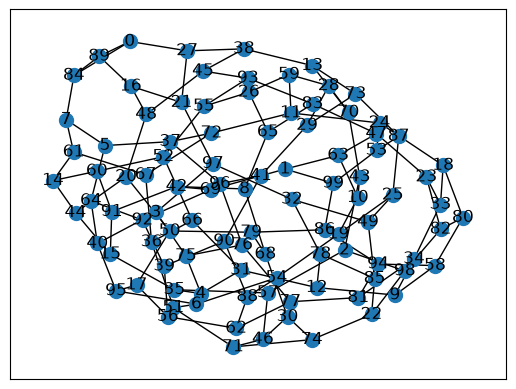

In [6]:
# Optionally, visualize the graph
nx.draw_networkx(
    maxcut_graph, nx.kamada_kawai_layout(maxcut_graph), node_size=100
)

The Solver accepts a string as the problem definition input.

In [7]:
# Convert graph to string
problem_as_str = nx.readwrite.json_graph.adjacency_data(maxcut_graph)

### 2. Run the problem
When using the graph-based input method, specify the problem type. Calculate the function size from `maxcut_graph`, then pass the returned value to `solver.run` through `function_size`.

In [8]:
# Calculate the workload size
maxcut_size = calculate_function_size(
    problem_as_str,
    problem_type="maxcut"
)

print(f"Workload size: {maxcut_size}")

Workload size: M


In [9]:
backend_name = catalog.least_busy().name

In [ ]:
# Solve the problem
maxcut_job = solver.run(
    problem=problem_as_str,
    problem_type="maxcut",
    backend_name=backend_name,  # E.g. "ibm_fez"
    function_size=maxcut_size,
)

Check your quantum function workload's [status](/docs/ibm-quantum-platform/functions-get-started#check-job-status) or return [results](/docs/ibm-quantum-platform/functions-get-started#retrieve-results) as follows:

In [17]:
# Print the ID so you can use it later, if necessary
print(maxcut_job.job_id)

# Get job status
print(maxcut_job.status())

eb364ea7-b69d-48f4-a1ce-1b22f2290534
RUNNING


### 3. Retrieve the result
Retrieve the optimal cut value from the results dictionary.

<Admonition type="note">
   The mapping of the variables to the bitstring may have changed. The output dictionary contains a `variables_to_bitstring_index_map` sub-dictionary, which helps to verify the ordering.
</Admonition>

In [18]:
# Poll for results
maxcut_result = maxcut_job.result()

# Take the absolute value of the solution since the cost function is minimized
qctrl_maxcut = abs(maxcut_result["solution_bitstring_cost"])

# Print the optimal cut value found by the Optimization Solver
print(f"Optimal cut value: {qctrl_maxcut}")

Optimal cut value: 137.0


You can verify the accuracy of the result by solving the problem classically with open-source solvers like [PuLP](https://coin-or.github.io/pulp/) if the graph is not densely connected. High density problems may require advanced classical solvers to validate the solution.

## Example: Constrained optimization
The prior max-cut example is a common quadratic unconstrained binary optimization problem. Q-CTRL's Optimization Solver can also solve constrained optimization problems by passing hard constraints directly to the Solver through the `constraint` input, instead of encoding them as penalty terms in the objective function. The Solver currently supports Hamming-weight-1 constraints: each constraint specifies a group of variables where exactly one variable must equal 1 and the rest must equal 0.

The following example demonstrates how to construct a cost function and a set of hard constraints for a constrained optimization problem, [graph partitioning](https://en.wikipedia.org/wiki/Graph_partition), by assigning every node in a graph to exactly one of several groups while minimizing the total weight of edges whose endpoints land in the same group.

In addition to the `qiskit-ibm-catalog` and `qiskit` packages, you will also use the following packages to run this example: `numpy`, `networkx`, and `sympy`. You can install these packages by uncommenting the following cell if you are running this example in a notebook using the IPython kernel.

In [11]:
# %pip install numpy networkx sympy

### 1. Define the problem
Define a random graph partitioning problem by generating a graph with randomly weighted nodes.

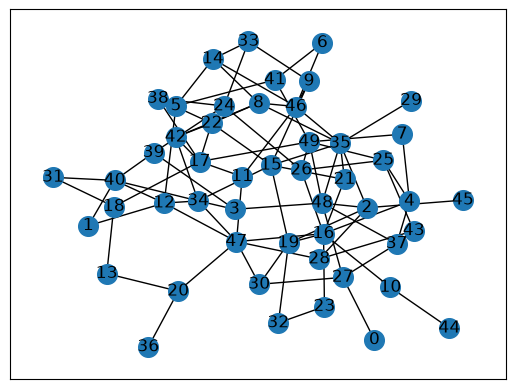

In [9]:
import networkx as nx
from sympy import Symbol, Poly, srepr

# To change the weights, change the seed to any integer.
rng_seed = 18
_rng = np.random.default_rng(rng_seed)
node_count = 50
edge_probability = 0.08
graph = nx.erdos_renyi_graph(
    node_count, edge_probability, seed=rng_seed, directed=False
)

# add node weights
min_weight = -1.0
max_weight = 1.0
for i in graph.nodes:
    weight = (max_weight - min_weight) * _rng.random() + min_weight
    graph.add_node(i, weight=weight)

# Optionally, visualize the graph
nx.draw_networkx(graph, nx.kamada_kawai_layout(graph), node_size=200)

A standard optimization model for weighted graph partitioning can be formulated as follows. Split the nodes of the graph into three groups $g \in \{0, 1, 2\}$, and let $n_{i,g} = 1$ if node $i$ is assigned to group $g$, and $n_{i,g} = 0$ otherwise. The goal is to minimize the total weight of edges whose endpoints are assigned to the same group, where the weight of an edge $(i,j)$ is the combined weight of its two endpoints, $\omega_{i,j} = \omega_i + \omega_j$:

$$\textbf{Minimize}\qquad y = \sum_{(i,j)\in E} \omega_{i,j} \sum_{g} n_{i,g}\, n_{j,g}$$

In [10]:
# Construct the cost function.
group_count = 3
variables = [
    Symbol(f"n[{i},{g}]")
    for i in range(node_count)
    for g in range(group_count)
]
node_group_var = {
    (i, g): variables[i * group_count + g]
    for i in range(node_count)
    for g in range(group_count)
}
cost_function = Poly(0, *variables)

for i, j in graph.edges():
    edge_weight = graph.nodes[i]["weight"] + graph.nodes[j]["weight"]
    for g in range(group_count):
        cost_function += (
            edge_weight * node_group_var[(i, g)] * node_group_var[(j, g)]
        )

Every node must be assigned to exactly one of the three groups. This is a Hamming-weight-1 constraint: for every node $i$, exactly one of $n_{i,0}, n_{i,1}, n_{i,2}$ must equal 1, and the rest must equal 0:

$$n_{i,0} + n_{i,1} + n_{i,2} = 1 \texttt{ for all } i \in V$$

Rather than encoding this requirement as a penalty term in the cost function, pass it directly to the Solver as a hard constraint using the `constraint` input.

In [11]:
# Build the hard constraint: exactly one group per node.
constraint_dict = {
    str(tuple(f"n[{i},{g}]" for g in range(group_count))): 1
    for i in range(node_count)
}
print(f"Problem constraints: {constraint_dict}")

Problem constraints: {"('n[0,0]', 'n[0,1]', 'n[0,2]')": 1, "('n[1,0]', 'n[1,1]', 'n[1,2]')": 1, "('n[2,0]', 'n[2,1]', 'n[2,2]')": 1, "('n[3,0]', 'n[3,1]', 'n[3,2]')": 1, "('n[4,0]', 'n[4,1]', 'n[4,2]')": 1, "('n[5,0]', 'n[5,1]', 'n[5,2]')": 1, "('n[6,0]', 'n[6,1]', 'n[6,2]')": 1, "('n[7,0]', 'n[7,1]', 'n[7,2]')": 1, "('n[8,0]', 'n[8,1]', 'n[8,2]')": 1, "('n[9,0]', 'n[9,1]', 'n[9,2]')": 1, "('n[10,0]', 'n[10,1]', 'n[10,2]')": 1, "('n[11,0]', 'n[11,1]', 'n[11,2]')": 1, "('n[12,0]', 'n[12,1]', 'n[12,2]')": 1, "('n[13,0]', 'n[13,1]', 'n[13,2]')": 1, "('n[14,0]', 'n[14,1]', 'n[14,2]')": 1, "('n[15,0]', 'n[15,1]', 'n[15,2]')": 1, "('n[16,0]', 'n[16,1]', 'n[16,2]')": 1, "('n[17,0]', 'n[17,1]', 'n[17,2]')": 1, "('n[18,0]', 'n[18,1]', 'n[18,2]')": 1, "('n[19,0]', 'n[19,1]', 'n[19,2]')": 1, "('n[20,0]', 'n[20,1]', 'n[20,2]')": 1, "('n[21,0]', 'n[21,1]', 'n[21,2]')": 1, "('n[22,0]', 'n[22,1]', 'n[22,2]')": 1, "('n[23,0]', 'n[23,1]', 'n[23,2]')": 1, "('n[24,0]', 'n[24,1]', 'n[24,2]')": 1, "('n[25,

<Admonition type="note" title="Partially constrained problems">
You do not need to add every variable to `constraint`. Any variable left out of the dictionary remains unconstrained, so you can mix hard-constrained groups of variables with free variables in the same problem.
</Admonition>

### 2. Run the problem

Calculate the function size using the binary decision variables and interactions from the objective function and constraints. This formulation uses one variable per node and group. Pass the calculated size to `solver.run` through `function_size`.

In [14]:
partition_size = calculate_function_size(
    problem=srepr(cost_function),
    constraint=constraint_dict,
)

print(f"Workload size: {partition_size}")

Workload size: L


In [22]:
num_variables = node_count * group_count
objective_pairs = graph.number_of_edges() * group_count
constraint_pairs = node_count * group_count * (group_count - 1) // 2

partition_size = calculate_function_size(
    num_variables,
    objective_pairs + constraint_pairs,
)

print(f"Workload size: {partition_size}")

Workload size: L


In [ ]:
# Solve the problem
partition_job = solver.run(
    problem=srepr(cost_function),
    constraint=constraint_dict,
    backend_name="ibm_marrakesh",  # E.g. "ibm_marrakesh"
    function_size=partition_size,
)

Check your quantum function workload's [status](/docs/ibm-quantum-platform/functions-get-started#check-job-status) or return [results](/docs/ibm-quantum-platform/functions-get-started#retrieve-results) as follows:

In [21]:
# Print the ID so you can use it later, if necessary
print(partition_job.job_id)

# Get job status
print(partition_job.status())

b8085944-f313-444e-be39-ea61b1b47ebd
QUEUED


### 3. Get the result
Retrieve the solution and analyze the results. The solution cost represents the total weight of edges whose endpoints ended up in the same group, so a lower cost indicates a better partitioning of the graph.

In [ ]:
partition_result = partition_job.result()
qctrl_cost = partition_result["solution_bitstring_cost"]
solution_bitstring = partition_result["solution_bitstring"]

# Print results
print(f"Total weight of same-group edges: {qctrl_cost}")
print(f"Solution bitstring: {solution_bitstring}")

Total weight of same-group edges: -36.5539
Solution bitstring: 100100100100100001100100100100100100100100100100100001010100010100100100100010001001100100100001100001100001010001001010100100100100100010100100100100


## Get support

For any questions or issues, [reach out to Q-CTRL](https://form.typeform.com/to/iuujEAEI?typeform-source=q-ctrl.com).

## Changelog

- 2026-08-10: Added support for hard (Hamming weight 1) constraints via the `constraint` input, and updated the constrained optimization example to use them.
- 2026-02-11: We now have support for `ibm_miami`

## Next steps

<Admonition type="tip" title="Recommendations">

- Request access to [Q-CTRL Optimization Solver](https://quantum.cloud.ibm.com/functions?id=q-ctrl-optimization-solver).
- Visit the [API reference](/docs/functions/q-ctrl-optimization-solver/api-reference) for this quantum function.
- Try the [Solve higher-order binary optimization problems with Q-CTRL's Optimization Solver](/docs/tutorials/solve-higher-order-binary-optimization-problems-with-q-ctrls-optimization-solver) tutorial.
- Review [Sachdeva, N., et al. (2024).  Quantum optimization using a 127-qubit gate-model IBM quantum computer can outperform quantum annealers for nontrivial binary optimization problems. arXiv preprint arXiv:2406.01743](https://arxiv.org/abs/2406.01743).
- Review [Loco, D., et al. (2026).  Practical protein-pocket hydration-site prediction for drug discovery on a quantum computer. arXiv preprint arXiv:2512.08390](https://arxiv.org/abs/2512.08390).
- Review the [Mazda](https://q-ctrl.com/case-study/tackling-a-costly-bottleneck-in-automotive-design) case study.
- Review the [Network Rail](https://q-ctrl.com/case-study/accelerating-the-schedule-for-quantum-enhanced-rail) case study.
- Review the [Australian Army](https://q-ctrl.com/case-study/improving-army-logistics-with-quantum-computing) case study.
- Review the [Transport for New South Wales](https://q-ctrl.com/case-study/delivering-quantum-computing-for-faster-commuting) case study.

</Admonition>